# Phase 6: Visualization & Polish
In this final notebook, we will create beautiful visualizations for your project report and presentation. We will perform **PCA** and **t-SNE** to visualize the 'Latent Space' (the AI's brain) and generate high-quality images of the best molecules.

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import torch
import torch.nn as nn
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from rdkit import Chem
from rdkit.Chem import Draw, QED

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 1. Load the Model and Data
We need to reload our VAE model and a small batch of our processed data so we can map them into the latent space.

In [3]:
# 1. Load Vocab
with open('../data/processed/vocab.json', 'r') as f:
    vocab_data = json.load(f)
int_to_char = vocab_data['int_to_char']
vocab_size = len(int_to_char)

# 2. Define Model
class MolecularVAE(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, latent_dim=64):
        super(MolecularVAE, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.encoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_var = nn.Linear(hidden_dim, latent_dim)
        self.decoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_z_to_hidden = nn.Linear(latent_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
        
    def encode(self, x):
        embedded = self.embedding(x)
        _, hidden = self.encoder_rnn(embedded)
        hidden = hidden.squeeze(0)
        mu = self.fc_mu(hidden)
        log_var = self.fc_var(hidden)
        return mu, log_var

    def decode_latent(self, z, max_len=120):
        hidden = self.fc_z_to_hidden(z).unsqueeze(0)
        current_input = torch.tensor([[1]], device=z.device) # <SOS>
        generated = []
        for _ in range(max_len):
            embedded = self.embedding(current_input)
            out, hidden = self.decoder_rnn(embedded, hidden)
            logits = self.fc_out(out)
            
            temperature = 1.0
            probs = torch.softmax(logits.squeeze(1) / temperature, dim=-1)
            next_char_idx = torch.multinomial(probs, 1)
            
            current_input = next_char_idx
            idx = next_char_idx.item()
            if idx == 2: # <EOS>
                break
            generated.append(idx)
        return generated

model = MolecularVAE(vocab_size=vocab_size).to(device)
model.load_state_dict(torch.load('../models/vae_final.pt', map_location=device, weights_only=True))
model.eval()

# 3. Load 1000 molecules from training data for visualization
print("Loading a sample of processed data...")
data = np.load('../data/processed/X_train.npy')
sample_tensors = torch.tensor(data[:1000], dtype=torch.long).to(device)
print(f"Loaded {sample_tensors.shape[0]} molecules.")

Loading a sample of processed data...
Loaded 1000 molecules.


## 2. Mapping the Latent Space
We will pass our sample molecules through the Encoder to get their `mu` (mean) vectors. This is the 64-dimensional coordinate of the molecule inside the AI's brain.

In [4]:
print("Extracting latent vectors (mu)...")
with torch.no_grad():
    mu, _ = model.encode(sample_tensors)
    latent_vectors = mu.cpu().numpy()

print(f"Latent Space Shape: {latent_vectors.shape}")

Extracting latent vectors (mu)...
Latent Space Shape: (1000, 64)


## 3. PCA & t-SNE Visualization
Humans can't visualize 64 dimensions. We use **PCA** and **t-SNE** to squash these 64 dimensions down to 2 dimensions (X and Y) so we can plot them on a scatter graph.

Running PCA...
Running t-SNE (this might take a few seconds)...


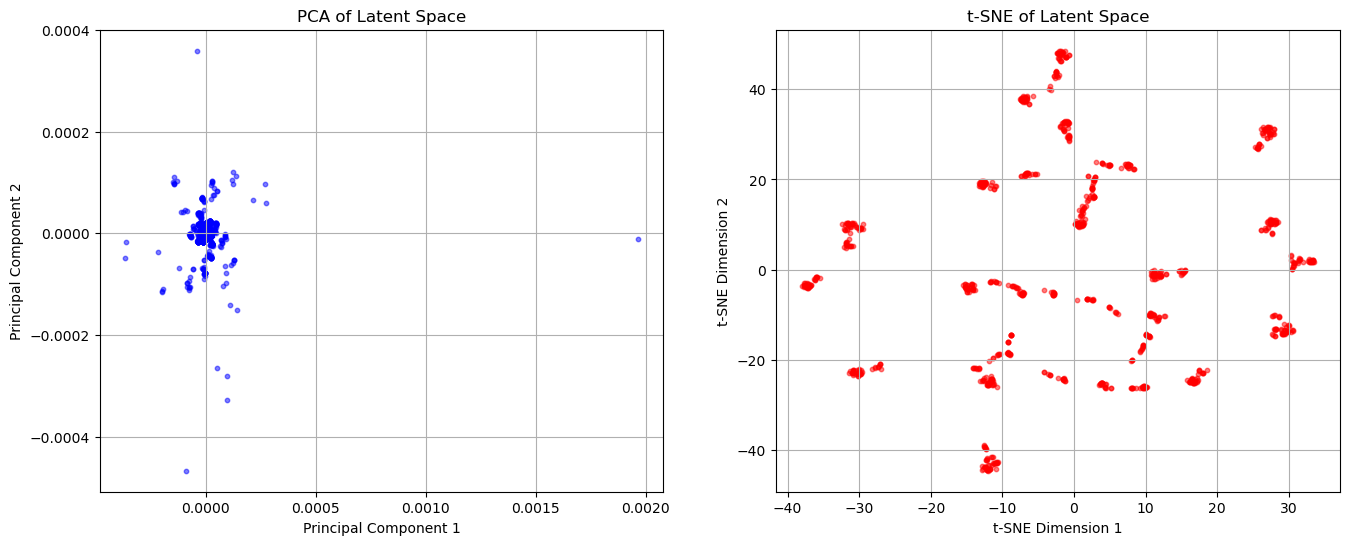

In [6]:
print("Running PCA...")
pca = PCA(n_components=2)
pca_result = pca.fit_transform(latent_vectors)

print("Running t-SNE (this might take a few seconds)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(latent_vectors)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

ax[0].scatter(pca_result[:, 0], pca_result[:, 1], alpha=0.5, c='blue', s=10)
ax[0].set_title('PCA of Latent Space')
ax[0].set_xlabel('Principal Component 1')
ax[0].set_ylabel('Principal Component 2')
ax[0].grid(True)

ax[1].scatter(tsne_result[:, 0], tsne_result[:, 1], alpha=0.5, c='red', s=10)
ax[1].set_title('t-SNE of Latent Space')
ax[1].set_xlabel('t-SNE Dimension 1')
ax[1].set_ylabel('t-SNE Dimension 2')
ax[1].grid(True)

plt.savefig('../results/plots/latent_space_visualization.png')
plt.show()

## 4. Final Polish: High-Quality Molecule Images
Let's generate a massive batch of molecules, find the absolute best ones (Highest QED scores), and save a beautiful high-resolution image of them for your final presentation.

Generating a large batch to find the best drugs...


[12:41:59] SMILES Parse Error: extra open parentheses while parsing: COc1ccc(NC(=O)CN/C(=C\c2ccccc2S(C)(=O)=O)s1

[12:41:59] SMILES Parse Error: check for mistakes around position 8:
[12:41:59] COc1ccc(NC(=O)CN/C(=C\c2ccccc2S(C)(=O)=O)
[12:41:59] ~~~~~~~^
[12:41:59] SMILES Parse Error: Failed parsing SMILES 'COc1ccc(NC(=O)CN/C(=C\c2ccccc2S(C)(=O)=O)s1
' for input: 'COc1ccc(NC(=O)CN/C(=C\c2ccccc2S(C)(=O)=O)s1
'
[12:41:59] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 25
[12:41:59] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 25
[12:41:59] Can't kekulize mol.  Unkekulized atoms: 12 13 14 15 23
[12:41:59] Can't kekulize mol.  Unkekulized atoms: 12 13 14 15 23
[12:41:59] SMILES Parse Error: extra close parentheses while parsing: CC(=O)NOC(=O)c1ccc(CN2CCC(=O)NC3=NC(SCc4c[nH]cn5)CC3)s2)cc1

[12:41:59] SMILES Parse Error: check for mistakes around position 56:
[12:41:59] (SCc4c[nH]cn5)CC3)s2)cc1

[12:41:59] ~~~~~~~~~~~~~~~~~~~~^
[12:41:59] SMILES Parse Error: Failed parsing SMILES 'CC(=O

Found 409 valid molecules out of 500!
Drawing the top 12 highest-scoring drugs...


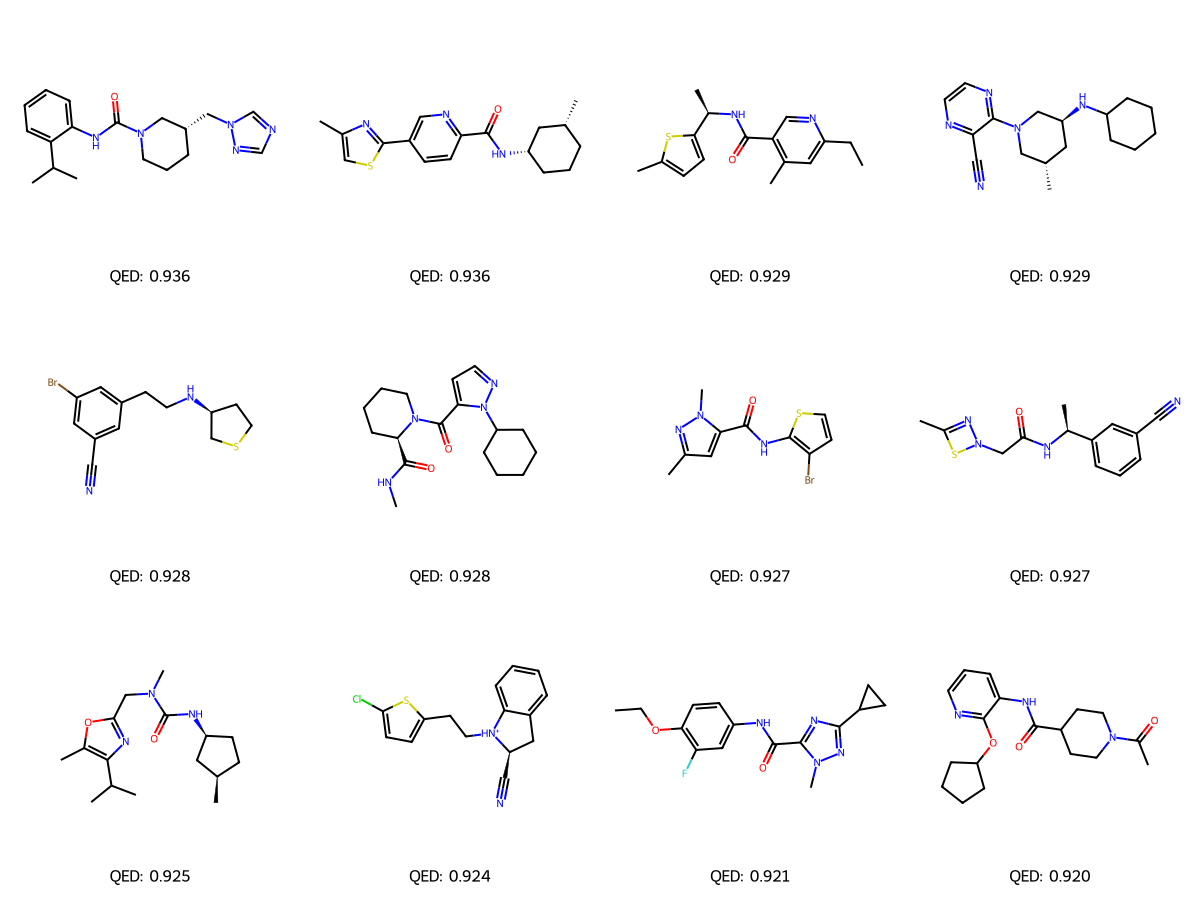

In [7]:
print("Generating a large batch to find the best drugs...")
num_samples = 500
best_mols = []

with torch.no_grad():
    z_random = torch.randn(num_samples, 64).to(device)
    for i in range(num_samples):
        z = z_random[i].unsqueeze(0)
        char_indices = model.decode_latent(z)
        smiles = ''.join([int_to_char[str(idx)] for idx in char_indices])
        mol = Chem.MolFromSmiles(smiles)
        
        if mol is not None:
            score = QED.qed(mol)
            best_mols.append((score, mol))

# Sort by highest QED score
best_mols.sort(key=lambda x: x[0], reverse=True)
top_mols_to_draw = [mol for score, mol in best_mols[:12]]
top_scores = [score for score, mol in best_mols[:12]]

print(f"Found {len(best_mols)} valid molecules out of {num_samples}!")
print("Drawing the top 12 highest-scoring drugs...")

img = Draw.MolsToGridImage(top_mols_to_draw, molsPerRow=4, subImgSize=(300, 300), 
                           legends=[f"QED: {score:.3f}" for score in top_scores], returnPNG=False)

img.save('../results/plots/top_generated_molecules.png')
display(img)